# Tugas - Klasifikasi dengan Support Vector Machine (SVM)

| Nama | NRP |
|------|-----|
| Fauzan Tamma Harish Kunfaza | 5054251035 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model SVM Classifier untuk menyelesaikan sebuah masalah klasifikasi.

Dataset dapat diakses melalui link berikut:
[Link dataset akan diinformasikan terpisah]

Tujuan utama dari tugas ini adalah memahami cara kerja SVM secara praktik, khususnya:
1. Perbedaan hasil antara kernel Linear dan kernel RBF
2. Pengaruh parameter `C` dan `gamma` terhadap gejala overfitting/underfitting

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan dalam membangun model, termasuk feature scaling.
3. Eksperimen Model
   - Bangun model SVM dengan kernel Linear dan kernel RBF.
   - Lakukan eksperimen regularisasi dengan variasi nilai `C` dan `gamma`.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil eksperimen dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42

In [2]:
df = pd.read_csv("data.csv")

print("Jumlah baris dan kolom:", df.shape)
print()
print("Tipe data tiap kolom:")
print(df.dtypes)
print()
print("Jumlah missing value per kolom (hanya yang > 0):")
print(df.isna().sum()[df.isna().sum() > 0])
print()
df.describe().T

Jumlah baris dan kolom: (569, 33)

Tipe data tiap kolom:
id                           int64
diagnosis                      str
radius_mean                float64
texture_mean               float64
perimeter_mean             float64
area_mean                  float64
smoothness_mean            float64
compactness_mean           float64
concavity_mean             float64
concave points_mean        float64
symmetry_mean              float64
fractal_dimension_mean     float64
radius_se                  float64
texture_se                 float64
perimeter_se               float64
area_se                    float64
smoothness_se              float64
compactness_se             float64
concavity_se               float64
concave points_se          float64
symmetry_se                float64
fractal_dimension_se       float64
radius_worst               float64
texture_worst              float64
perimeter_worst            float64
area_worst                 float64
smoothness_worst           float6

                         count          mean  ...           75%           max
id                       569.0  3.037183e+07  ...  8.813129e+06  9.113205e+08
radius_mean              569.0  1.412729e+01  ...  1.578000e+01  2.811000e+01
texture_mean             569.0  1.928965e+01  ...  2.180000e+01  3.928000e+01
perimeter_mean           569.0  9.196903e+01  ...  1.041000e+02  1.885000e+02
area_mean                569.0  6.548891e+02  ...  7.827000e+02  2.501000e+03
smoothness_mean          569.0  9.636028e-02  ...  1.053000e-01  1.634000e-01
compactness_mean         569.0  1.043410e-01  ...  1.304000e-01  3.454000e-01
concavity_mean           569.0  8.879932e-02  ...  1.307000e-01  4.268000e-01
concave points_mean      569.0  4.891915e-02  ...  7.400000e-02  2.012000e-01
symmetry_mean            569.0  1.811619e-01  ...  1.957000e-01  3.040000e-01
fractal_dimension_mean   569.0  6.279761e-02  ...  6.612000e-02  9.744000e-02
radius_se                569.0  4.051721e-01  ...  4.789000e-01 

diagnosis
B    357
M    212
Name: count, dtype: int64
diagnosis
B    0.627
M    0.373
Name: proportion, dtype: float64


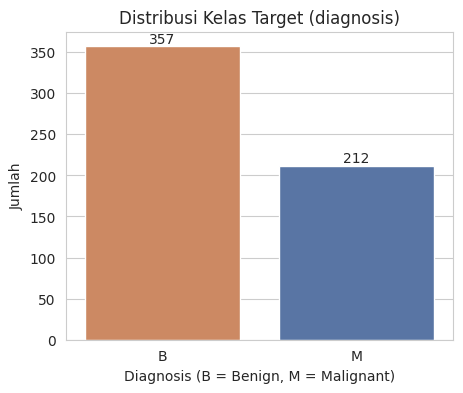

In [3]:
plt.figure(figsize=(5, 4))
ax = sns.countplot(data=df, x="diagnosis", hue="diagnosis", palette=["#4C72B0", "#DD8452"],
                    order=["B", "M"], legend=False)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom")
plt.title("Distribusi Kelas Target (diagnosis)")
plt.xlabel("Diagnosis (B = Benign, M = Malignant)")
plt.ylabel("Jumlah")
plt.show()

print(df["diagnosis"].value_counts())
print(df["diagnosis"].value_counts(normalize=True).round(3))

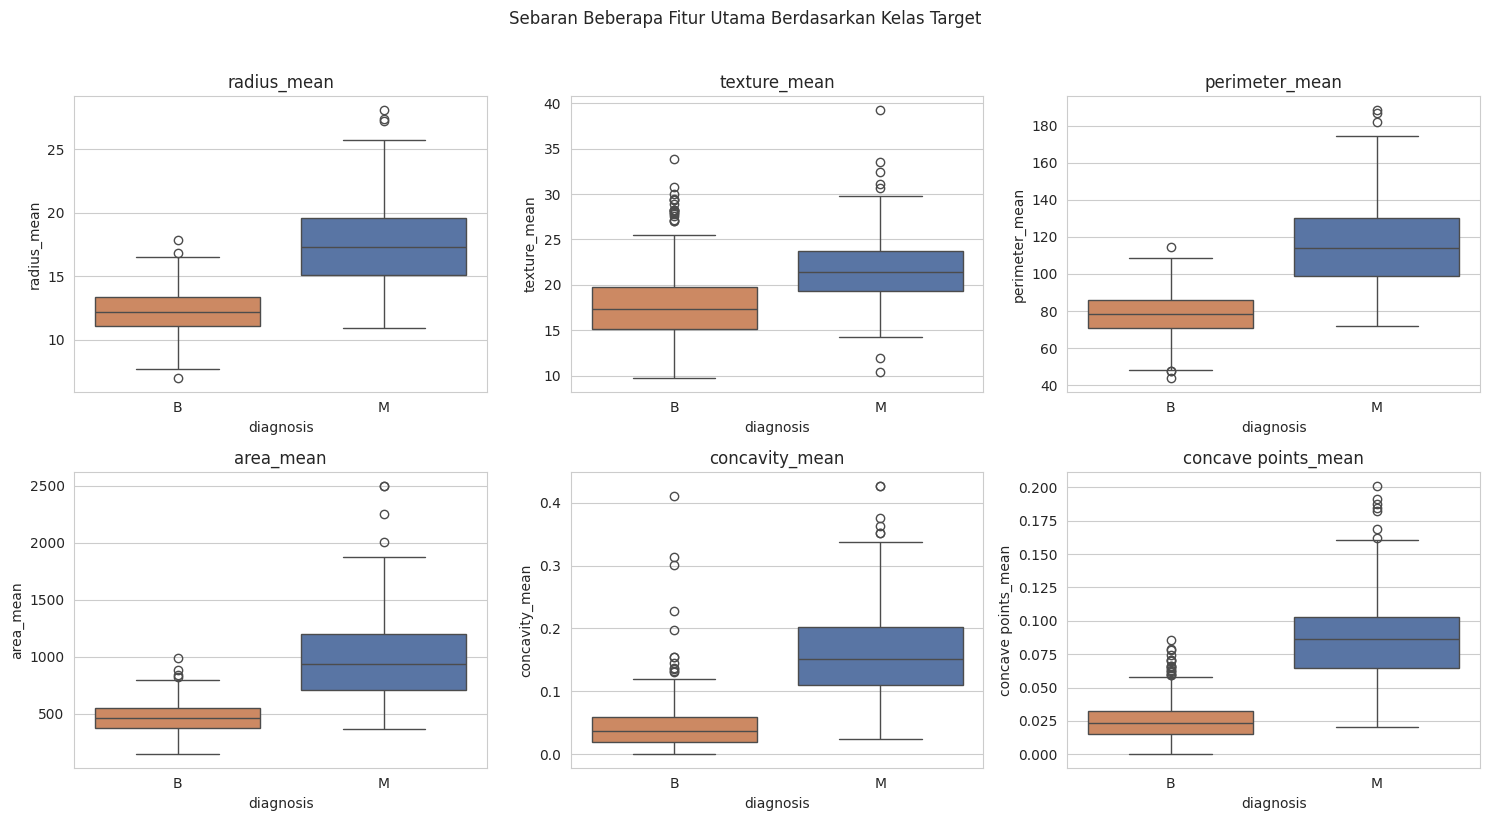

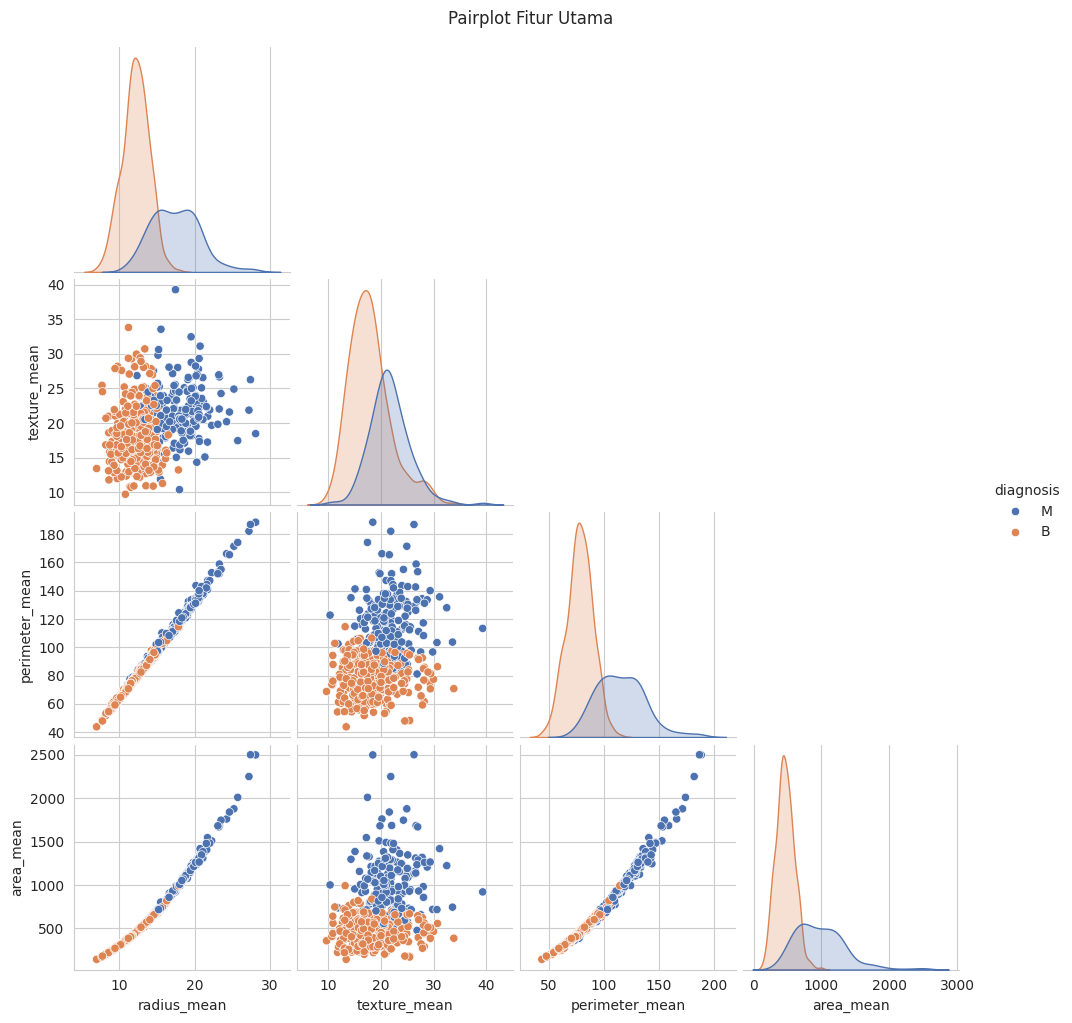

In [4]:
key_features = ["radius_mean", "texture_mean", "perimeter_mean",
                 "area_mean", "concavity_mean", "concave points_mean"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), key_features):
    sns.boxplot(data=df, x="diagnosis", y=col, hue="diagnosis", order=["B", "M"], ax=ax,
                palette=["#4C72B0", "#DD8452"], legend=False)
    ax.set_title(col)
plt.suptitle("Sebaran Beberapa Fitur Utama Berdasarkan Kelas Target", y=1.02)
plt.tight_layout()
plt.show()

sns.pairplot(df[key_features[:4] + ["diagnosis"]], hue="diagnosis",
             palette=["#4C72B0", "#DD8452"], corner=True)
plt.suptitle("Pairplot Fitur Utama", y=1.02)
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

Fitur dengan korelasi tertinggi terhadap radius_mean:
perimeter_mean     0.998
area_mean          0.987
radius_worst       0.970
perimeter_worst    0.965
area_worst         0.941
Name: radius_mean, dtype: float64


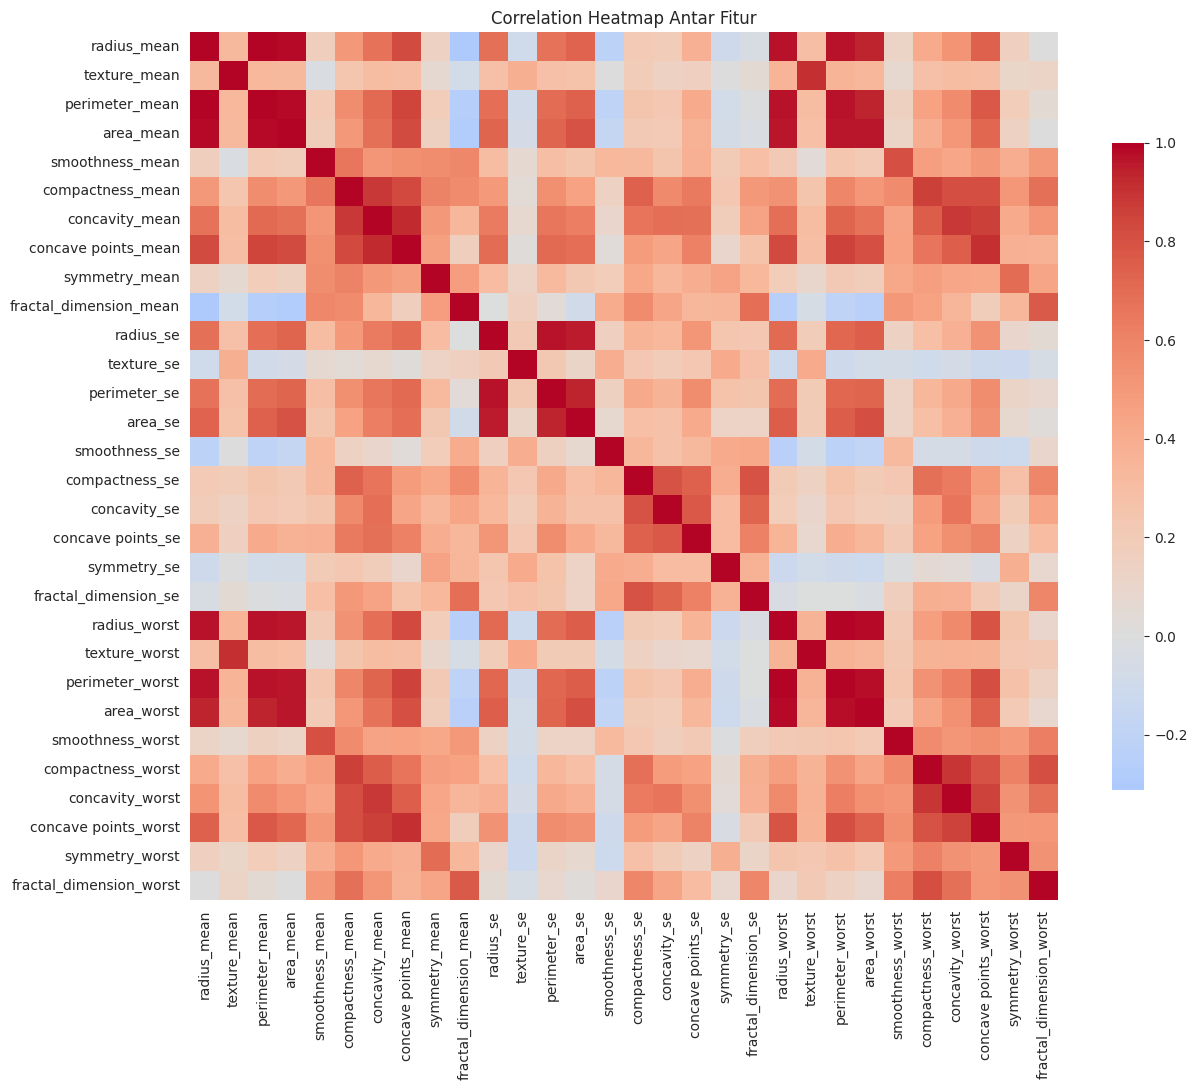

In [5]:
plt.figure(figsize=(14, 12))
numeric_cols = df.drop(columns=["id", "Unnamed: 32"], errors="ignore")
corr = numeric_cols.corr(numeric_only=True)
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": 0.7})
plt.title("Correlation Heatmap Antar Fitur")
plt.show()

top_corr = corr["radius_mean"].abs().sort_values(ascending=False)[1:6]
print("Fitur dengan korelasi tertinggi terhadap radius_mean:")
print(top_corr.round(3))

# 2. Preprocessing

In [6]:
# Kolom 'Unnamed: 32' seluruhnya kosong (artefak trailing comma saat export CSV),
# dan kolom 'id' hanya identifier, bukan fitur prediktif -> keduanya di-drop.
df_clean = df.drop(columns=["id", "Unnamed: 32"], errors="ignore")

print("Total missing value setelah pembersihan:", df_clean.isna().sum().sum())
df_clean.shape

Total missing value setelah pembersihan: 0


(569, 31)

In [7]:
# 'diagnosis' adalah kategorikal biner (M = Malignant, B = Benign) -> encode ke 1/0.
le = LabelEncoder()
df_clean["diagnosis"] = le.fit_transform(df_clean["diagnosis"])  # B=0, M=1
print("Mapping label:", dict(zip(le.classes_, le.transform(le.classes_))))
df_clean["diagnosis"].value_counts()

Mapping label: {'B': np.int64(0), 'M': np.int64(1)}


diagnosis
0    357
1    212
Name: count, dtype: int64

In [8]:
X = df_clean.drop(columns=["diagnosis"])
y = df_clean["diagnosis"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("X_train:", X_train.shape, " X_test:", X_test.shape)
print("Distribusi kelas y_train:\n", y_train.value_counts(normalize=True).round(3))
print("Distribusi kelas y_test:\n", y_test.value_counts(normalize=True).round(3))

X_train: (455, 30)  X_test: (114, 30)
Distribusi kelas y_train:
 diagnosis
0    0.626
1    0.374
Name: proportion, dtype: float64
Distribusi kelas y_test:
 diagnosis
0    0.632
1    0.368
Name: proportion, dtype: float64


**Catatan penting:** SVM adalah algoritma berbasis jarak (margin dihitung dari posisi antar titik data), sehingga sangat sensitif terhadap skala fitur. Fitur dengan rentang nilai besar bisa mendominasi perhitungan jarak meskipun sebenarnya tidak lebih penting. Lakukan **feature scaling** (misalnya `StandardScaler`) pada fitur numerik sebelum training. Ingat: `fit` scaler hanya pada train set, lalu `transform` ke train dan test set, agar tidak terjadi data leakage.

In [9]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

X_train_scaled.describe().T[["mean", "std"]].head()

                         mean       std
radius_mean     -1.737316e-16  1.001101
texture_mean     3.904081e-16  1.001101
perimeter_mean   4.704418e-16  1.001101
area_mean       -1.171224e-16  1.001101
smoothness_mean  7.242070e-16  1.001101

# 3. Eksperimen Model

## 3.1 SVM dengan Kernel Linear

Kernel Linear mencari hyperplane pemisah berupa garis/bidang lurus, tanpa proyeksi ke dimensi yang lebih tinggi. Cocok digunakan sebagai baseline, terutama jika dari hasil EDA data terlihat cukup terpisah secara linear.

In [10]:
svm_linear = SVC(kernel="linear", C=1, random_state=RANDOM_STATE)
svm_linear.fit(X_train_scaled, y_train)
svm_linear

SVC(C=1, kernel='linear', random_state=42)

In [11]:
y_pred_linear = svm_linear.predict(X_test_scaled)
print("Akurasi SVM Linear (test):", round(accuracy_score(y_test, y_pred_linear), 4))

Akurasi SVM Linear (test): 0.9649


## 3.2 SVM dengan Kernel RBF

Kernel RBF (Radial Basis Function) memproyeksikan data ke ruang berdimensi lebih tinggi melalui kernel trick, sehingga mampu menangani batas keputusan yang non-linear.

In [12]:
# Menggunakan C=1 (sama seperti model Linear) agar perbandingan adil.
svm_rbf = SVC(kernel="rbf", C=1, gamma="scale", random_state=RANDOM_STATE)
svm_rbf.fit(X_train_scaled, y_train)
svm_rbf

SVC(C=1, random_state=42)

In [13]:
y_pred_rbf = svm_rbf.predict(X_test_scaled)
print("Akurasi SVM RBF (test):", round(accuracy_score(y_test, y_pred_rbf), 4))

Akurasi SVM RBF (test): 0.9737


## 3.3 Eksperimen Regularisasi: Pengaruh C dan Gamma terhadap Overfitting

Parameter `C` mengatur trade-off antara margin lebar dan toleransi kesalahan klasifikasi, sedangkan `gamma` (khusus kernel RBF) mengatur seberapa lokal pengaruh tiap titik data. Pada bagian ini kalian akan mengamati bagaimana perubahan nilai `C` (dan/atau `gamma`) memengaruhi akurasi training dan testing.

In [14]:
C_values = [0.01, 0.1, 1, 10, 100]
models_C = {}

for C in C_values:
    model = SVC(kernel="rbf", C=C, gamma="scale", random_state=RANDOM_STATE)
    model.fit(X_train_scaled, y_train)
    models_C[C] = model

print("Model terlatih untuk C =", C_values)

Model terlatih untuk C = [0.01, 0.1, 1, 10, 100]


In [15]:
train_acc, test_acc = [], []

for C in C_values:
    model = models_C[C]
    train_acc.append(accuracy_score(y_train, model.predict(X_train_scaled)))
    test_acc.append(accuracy_score(y_test, model.predict(X_test_scaled)))

acc_table = pd.DataFrame({"C": C_values, "Train Accuracy": train_acc, "Test Accuracy": test_acc})
acc_table

        C  Train Accuracy  Test Accuracy
0    0.01        0.626374       0.631579
1    0.10        0.953846       0.947368
2    1.00        0.986813       0.973684
3   10.00        0.989011       0.973684
4  100.00        1.000000       0.964912

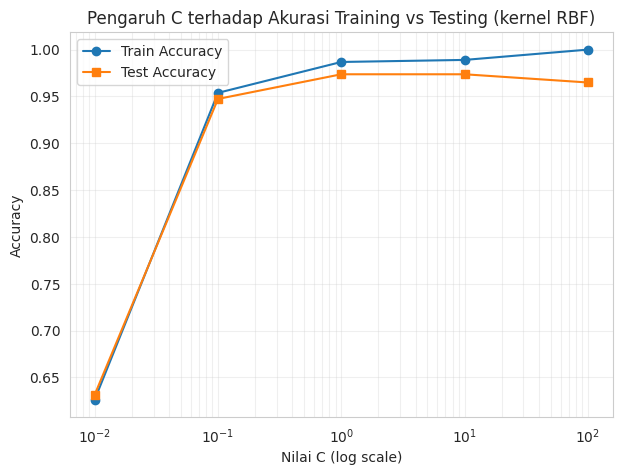

In [16]:
plt.figure(figsize=(7, 5))
plt.plot(C_values, train_acc, marker="o", label="Train Accuracy")
plt.plot(C_values, test_acc, marker="s", label="Test Accuracy")
plt.xscale("log")
plt.xlabel("Nilai C (log scale)")
plt.ylabel("Accuracy")
plt.title("Pengaruh C terhadap Akurasi Training vs Testing (kernel RBF)")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

# 4. Evaluasi Model

In [17]:
def eval_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-Score": f1_score(y_true, y_pred),
    }

metrics_df = pd.DataFrame({
    "SVM Linear": eval_metrics(y_test, y_pred_linear),
    "SVM RBF": eval_metrics(y_test, y_pred_rbf),
}).T.round(4)

metrics_df

            Accuracy  Precision  Recall  F1-Score
SVM Linear    0.9649        1.0  0.9048     0.950
SVM RBF       0.9737        1.0  0.9286     0.963

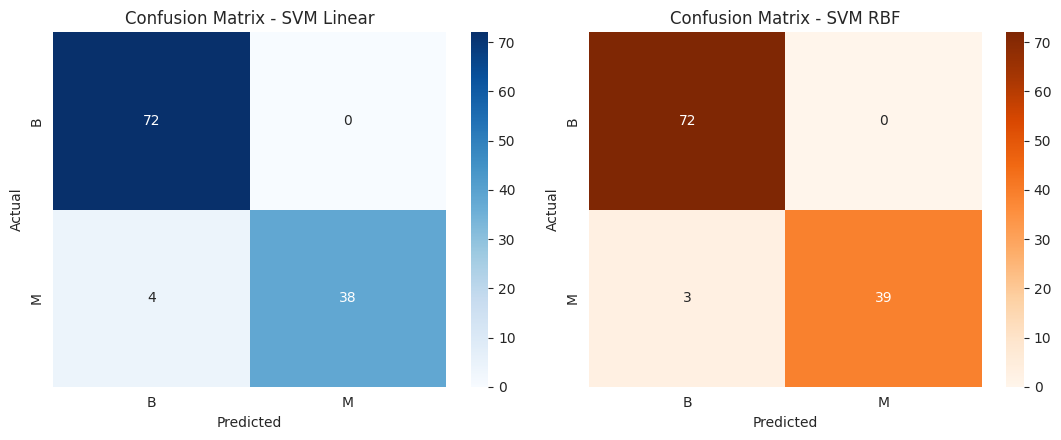

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

cm_linear = confusion_matrix(y_test, y_pred_linear)
cm_rbf = confusion_matrix(y_test, y_pred_rbf)

sns.heatmap(cm_linear, annot=True, fmt="d", cmap="Blues",
            xticklabels=["B", "M"], yticklabels=["B", "M"], ax=axes[0])
axes[0].set_title("Confusion Matrix - SVM Linear")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")

sns.heatmap(cm_rbf, annot=True, fmt="d", cmap="Oranges",
            xticklabels=["B", "M"], yticklabels=["B", "M"], ax=axes[1])
axes[1].set_title("Confusion Matrix - SVM RBF")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [19]:
best_name = "SVM RBF" if metrics_df.loc["SVM RBF", "F1-Score"] >= metrics_df.loc["SVM Linear", "F1-Score"] else "SVM Linear"
print("Model dengan performa terbaik (berdasarkan F1-Score):", best_name)
print()

sv_table = pd.DataFrame({
    "SVM Linear": [svm_linear.support_vectors_.shape[0], svm_linear.n_support_[0], svm_linear.n_support_[1]],
    "SVM RBF": [svm_rbf.support_vectors_.shape[0], svm_rbf.n_support_[0], svm_rbf.n_support_[1]],
}, index=["Total Support Vectors", "Support Vectors kelas B (0)", "Support Vectors kelas M (1)"])

sv_table

Model dengan performa terbaik (berdasarkan F1-Score): SVM RBF



                             SVM Linear  SVM RBF
Total Support Vectors                38      107
Support Vectors kelas B (0)          19       50
Support Vectors kelas M (1)          19       57

Variansi yang dijelaskan 2 komponen PCA: 63.14%
Jumlah support vectors pada model 2D (rbf): 91


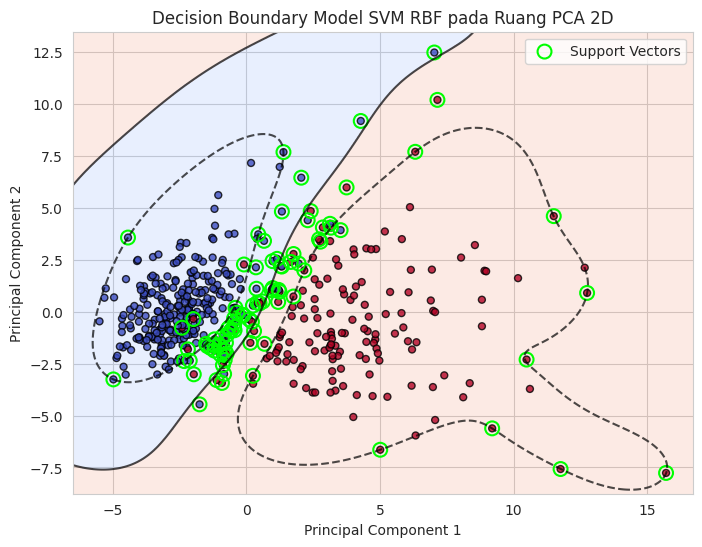

In [20]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print(f"Variansi yang dijelaskan 2 komponen PCA: {pca.explained_variance_ratio_.sum():.2%}")

kernel_best = "rbf" if best_name == "SVM RBF" else "linear"
model_2d = SVC(kernel=kernel_best, C=1, gamma="scale" if kernel_best == "rbf" else "auto",
               random_state=RANDOM_STATE)
model_2d.fit(X_train_pca, y_train)

x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
Z = model_2d.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z > 0, alpha=0.2, cmap="coolwarm")
plt.contour(xx, yy, Z, colors="k", levels=[-1, 0, 1], alpha=0.7, linestyles=["--", "-", "--"])
plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, cmap="coolwarm",
            edgecolors="k", s=25, alpha=0.8)
plt.scatter(model_2d.support_vectors_[:, 0], model_2d.support_vectors_[:, 1],
            facecolors="none", edgecolors="lime", s=100, linewidths=1.5, label="Support Vectors")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title(f"Decision Boundary Model {best_name} pada Ruang PCA 2D")
plt.legend()
plt.show()

print(f"Jumlah support vectors pada model 2D ({kernel_best}):", model_2d.support_vectors_.shape[0])

# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan.

Beberapa hal yang perlu dibahas:
- Bandingkan performa SVM dengan kernel Linear vs RBF. Apakah hasilnya berbeda signifikan? Menurut kalian, kenapa demikian, dikaitkan dengan bentuk sebaran data pada EDA?
- Jelaskan temuan dari eksperimen regularisasi (nilai `C`). Pada nilai berapa model mulai menunjukkan gejala overfitting? Bagaimana ciri-cirinya terlihat dari grafik akurasi training vs testing?
- Bandingkan jumlah support vectors antara model Linear dan RBF. Apa hubungan jumlah support vectors dengan kompleksitas batas keputusan yang terbentuk?

Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan, bukan hasil orang lain.

### Hasil Analisis

**1. Perbandingan performa SVM Linear vs RBF**

Pada eksperimen ini, SVM kernel Linear mencapai akurasi test sebesar **0.9649** (F1-Score 0.9500), sedangkan SVM kernel RBF mencapai akurasi test **0.9737** (F1-Score 0.9630). Selisih performa antara kedua kernel sangat tipis (di bawah 1%) (kernel RBF sedikit lebih unggul pada eksperimen ini). Hal ini konsisten dengan hasil EDA pada boxplot dan pairplot di awal notebook: fitur-fitur seperti `radius_mean`, `perimeter_mean`, `area_mean`, dan `concave points_mean` menunjukkan sebaran yang cukup terpisah antara kelas Benign dan Malignant, dengan overlap yang relatif terbatas. Karena data sudah relatif "mudah dipisahkan" pada ruang fitur aslinya, kernel Linear yang lebih sederhana mampu memberikan hasil yang kompetitif dibanding kernel RBF yang jauh lebih fleksibel — kompleksitas tambahan dari kernel RBF tidak banyak terpakai karena batas keputusan yang dibutuhkan memang sudah mendekati linear.

**2. Temuan eksperimen regularisasi (nilai C)**

Dari tabel dan grafik akurasi training vs testing terhadap nilai `C` (kernel RBF, C = [0.01, 0.1, 1, 10, 100]):
- Pada C kecil (0.01), akurasi training maupun testing sama-sama berada pada titik terendah (0.6264 train, 0.6316 test) — model masih *underfitting* karena margin terlalu lebar dan terlalu toleran terhadap kesalahan.
- Seiring C meningkat, akurasi training dan testing naik bersamaan hingga mencapai titik terbaik pada testing di C=1 (test accuracy 0.9737).
- Pada C=100, akurasi training mencapai 1.0000 sementara akurasi testing berada di 0.9649 (dibanding titik testing terbaik 0.9737 pada C=1). Pola di mana akurasi training terus naik mendekati sempurna sementara akurasi testing mulai stagnan/menurun adalah ciri khas gejala **overfitting**: model mulai terlalu menyesuaikan diri pada noise/detail data training akibat margin yang semakin sempit pada C besar, sehingga kemampuan generalisasinya ke data baru berkurang.

**3. Perbandingan jumlah support vectors**

Model Linear menghasilkan **38** support vectors, sedangkan model RBF menghasilkan **107** support vectors. Model RBF membutuhkan lebih banyak support vectors (107) dibanding Linear (38). Jumlah support vectors berkaitan erat dengan kompleksitas batas keputusan yang terbentuk: kernel RBF membentuk batas keputusan non-linear yang mengikuti kontur lokal data di ruang berdimensi tinggi, sehingga secara umum membutuhkan lebih banyak titik data di sekitar batas untuk mendefinisikan bentuknya, dibandingkan kernel Linear yang batas keputusannya berupa hyperplane lurus dan cukup didefinisikan oleh titik-titik yang berada tepat pada margin.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan.

Saran dapat berupa rekomendasi untuk eksperimen selanjutnya (misalnya mencoba kernel Polynomial, melakukan hyperparameter tuning dengan GridSearchCV, atau membandingkan dengan model lain), perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

### Kesimpulan

Berdasarkan seluruh eksperimen yang dilakukan pada dataset klasifikasi kanker payudara ini (569 sampel, 30 fitur numerik, kelas Benign 357 dan Malignant 212), SVM terbukti menjadi algoritma yang efektif, dengan performa terbaik dicapai oleh model **SVM RBF** (Accuracy 0.9737, F1-Score 0.9630 pada data testing). Satu hal yang terbukti krusial adalah **feature scaling**, karena SVM adalah algoritma berbasis jarak/margin sehingga sangat sensitif terhadap perbedaan skala antar fitur (misalnya `area_mean` yang bernilai ratusan hingga ribuan dibanding `smoothness_mean` yang bernilai desimal kecil).

Baik kernel Linear maupun RBF mampu memberikan performa tinggi pada dataset ini, dengan kernel Linear menjadi baseline yang kuat karena sebagian besar fitur sudah cukup terpisah secara linear antar kelas. Parameter `C` terbukti berperan penting sebagai pengatur trade-off antara bias dan varians: nilai C yang terlalu besar berisiko overfitting (akurasi training tinggi tetapi testing stagnan/menurun), sementara nilai C yang terlalu kecil berisiko underfitting, sehingga pemilihan C perlu selalu mempertimbangkan performa pada data testing, bukan hanya training.

**Saran untuk eksperimen selanjutnya:**
- Melakukan hyperparameter tuning yang lebih sistematis dengan `GridSearchCV`/`RandomizedSearchCV` (mengombinasikan pencarian `C` dan `gamma` sekaligus dengan cross-validation k-fold) agar hasil lebih robust dan tidak bergantung pada satu kali train-test split.
- Mencoba kernel Polynomial sebagai pembanding tambahan terhadap Linear dan RBF.
- Melakukan feature selection atau reduksi dimensi (memanfaatkan hasil correlation heatmap yang menunjukkan banyak fitur `*_mean`, `*_worst` saling berkorelasi tinggi) untuk mengurangi redundansi fitur.
- Membandingkan SVM dengan model lain seperti Logistic Regression atau Random Forest, mengingat ukuran dataset yang relatif kecil (569 baris) membuat hasil evaluasi rawan terhadap varians dari satu split data saja — idealnya divalidasi dengan cross-validation.